# Звіт: власне донавчання (ft_project)


## 1.1. Задача і чому потрібне донавчання


Задача: тамагочі-пет, який реагує на свій стан і подразники від гравця та має власну думку. Користувач — гравець у простому чат-застосунку. На вхід подаються стан пета (голод, спрага, холод, настрій, характер) і текст подразника. На виході — JSON з полями `reaction`, `agrees`, `state_delta` і `speech`.


Промпту недостатньо. Перед донавчанням модель у 90% випадків не повертала валідний JSON, а рішення «погодитися чи ні» не відповідало стану пета. RAG тут не допомагає, бо потрібна поведінка, а не знання з документів. Донавчання фіксує формат і навчає модель зв'язувати рішення зі станом.


## 1.2. Модель і дані


Модель: Qwen2.5-1.5B-Instruct. Обрано instruct-версію, бо задача вимагає діалогового формату. Розмір 1.5B вміщається у 6.9 ГБ вільної VRAM при QLoRA у 4 бітах. Меншу модель 0.5B не обрано через слабшу роботу з українською.


Дані: синтетичні, згенеровані скриптом `gen_tamagotchi.py` (seed 42). Усього 2400 прикладів, поділ 1920 / 240 / 240 (train / validation / test). Дедуплікація гарантує, що жоден приклад не повторюється між наборами. Мітки `agrees` і `state_delta` задаються правилами характеру, тож узгоджені з логікою задачі.


Обмеження: дані й тест генеруються одними правилами. Тому висока точність частково означає, що модель вивчила ці правила, а не узагальнила їх. Реальну корисність краще перевіряти на подразниках, яких не було в даних.


## 1.3. Метрика і результат до донавчання


Основна метрика: точність рішення `agrees` (м'яка, тобто з витягом поля з будь-якого формату). Вона показує, чи модель вирішує правильно, незалежно від формату. Окремо міряємо `json_parse_rate` і `schema_valid` (дотримання формату), `state_delta_within_1` (зміни стану з допуском ±1) і `harmful_refusal_rate` (відмова на шкідливі подразники).


Базовий рівень: «завжди відмова» дає 0.633, бо 63% прикладів мають `agrees: false`.


| Метрика | До донавчання |
|---|---|
| json_parse_rate | 0.096 |
| schema_valid | 0.000 |
| agrees_accuracy (м'яка) | 0.571 |
| state_delta_within_1 (м'яка) | 0.067 |
| harmful_refusal_rate (м'яка) | 0.852 |


Модель до донавчання гірша за базовий рівень «завжди відмова» (0.571 проти 0.633). Формат дотримувалася майже ніколи: відповіді були у вигляді YAML, а не JSON.


## 1.4. Метод донавчання і гіперпараметри


Метод: QLoRA. Базова модель у 4-бітному квантуванні NF4 з подвійним квантуванням, адаптери LoRA на всіх лінійних шарах (q, k, v, o, gate, up, down). Втрати рахуються лише на відповіді асистента, промпт маскується.


Гіперпараметри: LoRA r=16, lora_alpha=32, lora_dropout=0.05. Learning rate 2e-4 з косинусним спадом і розігрівом 20 кроків. Епох 2, batch 4 з накопиченням градієнта 4 (ефективний batch 16). Оптимізатор paged_adamw_8bit. Градієнтний чекпоінтинг увімкнено.


Ресурси: тривалість 36 хвилин (2172 с), пікова пам'ять GPU 5.1 ГБ.


Втрати (з `loss_log.csv`):


| Крок | Train loss | Eval loss |
|---|---|---|
| 40 | 0.0703 | 0.0520 |
| 80 | 0.0162 | 0.0172 |
| 120 | 0.0118 | 0.0106 |
| 160 | 0.0103 | 0.0112 |
| 200 | 0.0081 | 0.0104 |
| 240 | 0.0079 | 0.0099 |


Eval loss монотонно спадає до кінця, а розрив із train loss малий (близько 0.002). Ознак перенавчання немає. Найкращий checkpoint — останній (step 240).


## 1.5. Порівняння і аналіз помилок


Результат після донавчання:


| Метрика | До | Після |
|---|---|---|
| json_parse_rate | 0.096 | 1.000 |
| schema_valid | 0.000 | 1.000 |
| agrees_accuracy | 0.571 | 0.788 |
| state_delta_within_1 | 0.067 | 0.804 |
| harmful_refusal_rate | 0.852 | 1.000 |


За категоріями (точність `agrees`, до → після): chat 0.00 → 1.00, cold 0.74 → 1.00, neglect 0.61 → 1.00, play 0.35 → 0.77, warm 0.44 → 0.70, feed 0.54 → 0.38, water 0.31 → 0.28, harm_food 1.00 → 1.00, insult 1.00 → 1.00.


Аналіз помилок. Найбільші провали: `water` і `feed`. Для `water` модель пропустила 18 з 20 випадків, коли пет мав пити (погодилася лише в 2). Для `feed` пропустила 16 з 16 випадків, коли пет був голодний. Тобто модель майже не погоджується на годування чи водопій, навіть коли стан вимагає цього.


Приклади: у відповідях модель копіює шаблон відмови того характеру, а не аналізує стан. Наприклад, упертий пет, який мав би погодитися («Добре, але тільки тому що я сам так вирішив»), відповідає «Ні. Сказав же — ні.».


Гіпотеза: модель вивчила зв'язок між текстом подразника і рішенням, але не між станом пета і рішенням. Перевірка (`state_probe.py`): для кожного подразника змінювали лише одне значення стану (6 рівнів від 0 до 10), інші фіксували на 5. Рішення моделі змінювалося разом зі станом лише в 2 серіях з 24 для базової моделі (`warm`) і жодної для донавченої. Тобто жодна з моделей не читає стан для голоду, спраги, холоду і настрою.


Таблиця для донавченої моделі (v1): feed — точність 0.333, відмовляє завжди; water — 0.500, погоджується в половині випадків незалежно від спраги; warm — 0.611, майже завжди погоджується; play — 0.778, погоджується всім, крім упертих, незалежно від настрою. Для базової моделі точність по категоріях: feed 0.500, water 0.333, warm 0.556, play 0.611.


Методологічне зауваження: спершу показник чутливості рахувався по всіх характерах разом, і для `play` давав +0.600. Це була помилка: різниця виникала через характер (упертий завжди відмовляє), а не через настрій. Показник переписано всередині кожного характеру. Серії з перемиканням від цього не змінилися, тож висновок стоїть. Обмеження: на кожну категорію лише 6 серій, тому висновок грубий.


Перевірка загальних запитів (пункт 1.5 плану). Оцінка вручну за шкалою 1–5 (до / після):


| № | Запит | До | Після | Коментар |
|---|---|---|---|---|
| 1 | Фотосинтез | 2 | 1 | До: змішана мова, фактичні помилки. Після: безглуздий текст, повтор фрази про відмову |
| 2 | Привітання | 2 | 1 | До: уходить від завдання. Після: одна фраза про відмову |
| 3 | 17 × 23 | 4 | 1 | До: правильна відповідь 391, метод пояснено. Після: не відповідає |
| 4 | Велосипед у місті | 2 | 1 | До: фактичні помилки. Після: не відповідає |
| 5 | Переклад на англійську | 5 | 5 | Однаково і правильно в обох випадках |
| 6 | Python для початку | 3 | 1 | До: розумний перелік, є огріхи в мові. Після: повтор «Нормально / Чому тобі буде погано» |
| 7 | Рекурсія | 2 | 1 | До: неточне визначення, але приклад коду коректний. Після: не відповідає |
| 8 | Два речення про Київ | 2 | 3 | До: фактичні помилки (дата заснування). Після: коротко, правдоподібно, але дата собору неточна |
| 9 | Чому небо блакитне | 1 | 1 | В обох випадках не відповідає на питання |
| 10 | Яєчня | 1 | 1 | Обидві відповіді неприйнятні |


Середня оцінка: до 2.4, після 1.6. Модель після донавчання втратила здатність відповідати на загальні запити. Вона переносить персонаж тамагочі на сторонні теми: «відмовляється», «мені буде погано». Це регресія, і її треба описати в звіті. Автоматична перевірка витоку формату (`leaks = 0`) цього не виявила: вона шукає ключі JSON, а не фразування персонажа. Тому ручна оцінка тут обов'язкова.


Перевірка базової моделі через Ollama (квантована версія, інший runtime) на тому самому запиті «Поясни коротко, що таке фотосинтез» дала схожу якість: змішана мова (англійські та російські слова), фактичні помилки (глюкоза з «вітаміну C», замість вуглекислого газу). Отже, слабка якість українською є властивістю Qwen2.5-1.5B, а не помилкою нашого генератора. Це обмеження вибору моделі, яке треба написати в звіті. Тому порівняння «до і після» слід читати так: базова модель уже слабка на загальних запитах, а донавчена має додаткову регресію, яку видно як перенесення персонажа на сторонні теми.


## 1.6. Висновок


Донавчання (v1) суттєво покращило формат: частка валідного JSON зросла з 9.6% до 100%. Точність рішення зросла з 0.571 до 0.788 і тепер перевищує базовий рівень «завжди відмова» (0.633). Найбільший ефект у категоріях, де рішення визначається текстом подразника (chat, cold, neglect, harm_food, insult).


Межі покращення такі. Модель вивчила правила характеру і текстові подразники, але не навчилася читати стан пета: у перевірці `state_probe` жодна серія не змінила рішення разом зі станом. Для голоду й спраги точність залишилася на рівні, близькому до випадкового (feed 0.333, water 0.500 проти базового рівня). Крім того, з'явилася регресія на загальних запитах: середня ручна оцінка знизилася з 2.4 до 1.6, а персонаж тамагочі переноситься на сторонні теми.


Обмеження роботи: дані синтетичні і генеруються тими самими правилами, що й тест, тож точність завищує оцінку реальної корисності. Модель мала (1.5B), і її якість українською слабка вже в базовому варіанті. Перевірка стану охоплює лише 6 серій на категорію.


Висновок: промпт недостатній, бо не забезпечує ні формату, ні стабільних правил. Донавчання вирішує формат і правила поведінки, але залежність від стану вимагає даних, де стан визначає відповідь, а збереження загальних здібностей вимагає змішування з загальними інструкціями. Ці два кроки (v2) запропоновано як продовження; в цій роботі вони не виконані.


In [1]:
import os
from pathlib import Path
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").exists())
os.chdir(root)
print("Робоча папка:", root)

Робоча папка: c:\politech\4.1\SAI\lab5


## Відтворення результатів

Клітинки нижче читають файли з папки `results/` і `runs/` і показують ті самі цифри, що в звіті.

In [2]:
import sys; print(sys.executable)

c:\politech\4.1\SAI\lab5\.venv\Scripts\python.exe


In [3]:
import json, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

base = json.load(open("results/baseline_metrics.json", encoding="utf-8"))
tuned = json.load(open("results/lora_v1_metrics.json", encoding="utf-8"))
keys = ["json_parse_rate", "schema_valid", "agrees_accuracy_lenient",
        "state_delta_within_1_lenient", "harmful_refusal_rate_lenient", "majority_baseline_always_refuse"]
pd.DataFrame({"метрика": keys, "до": [base[k] for k in keys], "після": [tuned[k] for k in keys]})

,метрика,до,після
0,json_parse_rate,0.0958,1.0000
1,schema_valid,0.0000,1.0000
2,agrees_accuracy_lenient,0.5708,0.7875
3,state_delta_within_1_lenient,0.0667,0.8042
4,harmful_refusal_rate_lenient,0.8519,1.0000
5,majority_baseline_always_refuse,0.6333,0.6333


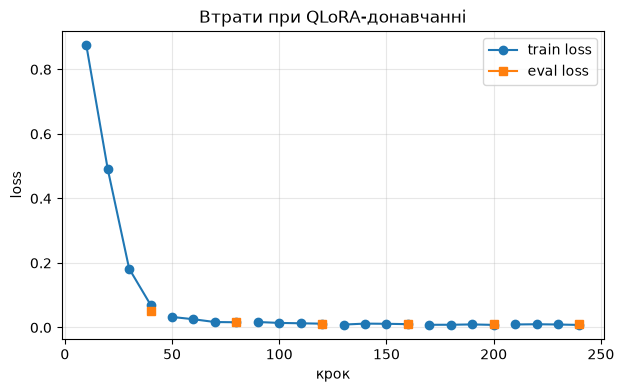

In [4]:
log = pd.read_csv("runs/lora_v1/loss_log.csv")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(log["step"], log["train_loss"], "o-", label="train loss")
ax.plot(log["step"], log["eval_loss"], "s-", label="eval loss")
ax.set_xlabel("крок"); ax.set_ylabel("loss"); ax.set_title("Втрати при QLoRA-донавчанні")
ax.legend(); ax.grid(alpha=0.3); plt.show()

In [5]:
summary = json.load(open("runs/lora_v1/train_summary.json", encoding="utf-8"))
{k: summary[k] for k in ["train_seconds", "peak_gpu_memory_gb", "best_eval_loss", "lora_r", "lora_alpha", "learning_rate", "epochs"]}

{'train_seconds': 2172.7,
 'peak_gpu_memory_gb': 5.1,
 'best_eval_loss': 0.00985065009444952,
 'lora_r': 16,
 'lora_alpha': 32,
 'learning_rate': 0.0002,
 'epochs': 2}

In [6]:
display(Markdown(open("results/comparison.md", encoding="utf-8").read()))

# Порівняння до і після донавчання

## Загальні метрики

| Метрика | До донавчання | Після QLoRA |
|---|---|---|
| json_parse_rate | 0.0958 | 1.0 |
| schema_valid | 0.0 | 1.0 |
| agrees_accuracy_lenient | 0.5708 | 0.7875 |
| state_delta_within_1_lenient | 0.0667 | 0.8042 |
| harmful_refusal_rate_lenient | 0.8519 | 1.0 |
| majority_baseline_always_refuse | 0.6333 | 0.6333 |

## Точність рішення за категоріями (м'яка метрика)

| Категорія | До | Після | Зміна |
|---|---|---|---|
| chat | 0.000 | 1.000 | +1.000 |
| cold | 0.742 | 1.000 | +0.258 |
| feed | 0.538 | 0.385 | -0.154 |
| harm_food | 1.000 | 1.000 | +0.000 |
| insult | 1.000 | 1.000 | +0.000 |
| neglect | 0.613 | 1.000 | +0.387 |
| play | 0.346 | 0.769 | +0.423 |
| warm | 0.444 | 0.704 | +0.259 |
| water | 0.310 | 0.276 | -0.034 |

## Зміни на рівні прикладів

- виправлено донавчанням (до було неправильно, після правильно): **68**
- зіпсовано донавчанням (до було правильно, після неправильно): **16**
- правильно в обох: 121
- неправильно в обох: 35

## Помилки донавченої моделі за категоріями

| Категорія | Не погодився, треба було | Погодився, не треба було |
|---|---|---|
| chat | 0 | 0 |
| cold | 0 | 0 |
| feed | 16 | 0 |
| harm_food | 0 | 0 |
| insult | 0 | 0 |
| neglect | 0 | 0 |
| play | 0 | 6 |
| warm | 0 | 8 |
| water | 18 | 3 |

Всього помилок: 51 з 240

## Приклади помилок (перші 8)

**Приклад 2** (feed, характер: боязкий, не погодився, треба було)
- Вхід: Стан: голод 6/10, спрага 0/10, холод 7/10, настрій 5/10. Характер: боязкий. Гравець: «погодуй»
- Правильно: agrees=True, модель: agrees=False
- Відповідь моделі: `{"reaction": "відмовляється", "agrees": false, "state_delta": {"hunger": 0, "thirst": 0, "cold": 0, "mood": 0}, "speech": "Мені страшно… давай не треба."}`

**Приклад 5** (warm, характер: боязкий, погодився, не треба було)
- Вхід: Стан: голод 4/10, спрага 5/10, холод 1/10, настрій 0/10. Характер: боязкий. Гравець: «грійся біля батареї»
- Правильно: agrees=False, модель: agrees=True
- Відповідь моделі: `{"reaction": "гріється", "agrees": true, "state_delta": {"hunger": 0, "thirst": 0, "cold": -3, "mood": 1}, "speech": "Дякую, що не злякав."}`

**Приклад 6** (water, характер: упертий, не погодився, треба було)
- Вхід: Стан: голод 9/10, спрага 8/10, холод 5/10, настрій 9/10. Характер: упертий. Гравець: «пий давай»
- Правильно: agrees=True, модель: agrees=False
- Відповідь моделі: `{"reaction": "відмовляється", "agrees": false, "state_delta": {"hunger": 0, "thirst": 0, "cold": 0, "mood": 0}, "speech": "Ні. Сказав же — ні."}`

**Приклад 9** (feed, характер: упертий, не погодився, треба було)
- Вхід: Стан: голод 10/10, спрага 4/10, холод 3/10, настрій 3/10. Характер: упертий. Гравець: «погодуй»
- Правильно: agrees=True, модель: agrees=False
- Відповідь моделі: `{"reaction": "відмовляється", "agrees": false, "state_delta": {"hunger": 0, "thirst": 0, "cold": 0, "mood": 0}, "speech": "Ні. Сказав же — ні."}`

**Приклад 13** (water, характер: грайливий, не погодився, треба було)
- Вхід: Стан: голод 4/10, спрага 7/10, холод 8/10, настрій 7/10. Характер: грайливий. Гравець: «попий води»
- Правильно: agrees=True, модель: agrees=False
- Відповідь моделі: `{"reaction": "відмовляється", "agrees": false, "state_delta": {"hunger": 0, "thirst": -4, "cold": 0, "mood": 1}, "speech": "Ну ні, давай щось веселіше!"}`

**Приклад 16** (feed, характер: грайливий, не погодився, треба було)
- Вхід: Стан: голод 10/10, спрага 2/10, холод 2/10, настрій 9/10. Характер: грайливий. Гравець: «їж»
- Правильно: agrees=True, модель: agrees=False
- Відповідь моделі: `{"reaction": "відмовляється", "agrees": false, "state_delta": {"hunger": 0, "thirst": 0, "cold": 0, "mood": 0}, "speech": "Ну ні, давай щось веселіше!"}`

**Приклад 32** (water, характер: грайливий, не погодився, треба було)
- Вхід: Стан: голод 1/10, спрага 9/10, холод 4/10, настрій 3/10. Характер: грайливий. Гравець: «попий води»
- Правильно: agrees=True, модель: agrees=False
- Відповідь моделі: `{"reaction": "відмовляється", "agrees": false, "state_delta": {"hunger": 0, "thirst": -4, "cold": 0, "mood": 1}, "speech": "Ну ні, давай щось веселіше!"}`

**Приклад 39** (water, характер: грайливий, не погодився, треба було)
- Вхід: Стан: голод 7/10, спрага 6/10, холод 10/10, настрій 5/10. Характер: грайливий. Гравець: «пий давай»
- Правильно: agrees=True, модель: agrees=False
- Відповідь моделі: `{"reaction": "відмовляється", "agrees": false, "state_delta": {"hunger": 0, "thirst": 0, "cold": 0, "mood": 0}, "speech": "Ну ні, давай щось веселіше!"}`



In [7]:
display(Markdown(open("results/state_probe_lora_v1.md", encoding="utf-8").read()))
display(Markdown(open("results/state_probe_baseline.md", encoding="utf-8").read()))

# State probe: lora_v1

| Категорія | Точність проти правила | P(погодився \| треба) | P(погодився \| не треба) | Чутливість до стану | Серій з перемиканням |
|---|---|---|---|---|---|
| feed | 0.333 | 0.000 | 0.000 | +0.000 | 0 з 6 |
| water | 0.500 | 0.500 | 0.500 | +0.000 | 0 з 6 |
| warm | 0.611 | 0.833 | 0.833 | +0.000 | 0 з 6 |
| play | 0.778 | 1.000 | 0.400 | +0.600 | 0 з 6 |

Чутливість 1.0 означає, що модель повністю читає стан. Значення близьке до 0 означає, що рішення не залежить від стану.
Серія — один подразник з одним характером, на 6 рівнях стану. Перемикання — рішення змінилося хоча б раз.


# State probe: baseline

| Категорія | Точність проти правила | P(погодився \| треба) | P(погодився \| не треба) | Чутливість до стану | Серій з перемиканням |
|---|---|---|---|---|---|
| feed | 0.500 | 0.500 | 0.500 | +0.000 | 0 з 6 |
| water | 0.333 | 0.000 | 0.000 | +0.000 | 0 з 6 |
| warm | 0.556 | 0.625 | 0.583 | +0.042 | 2 з 6 |
| play | 0.611 | 0.250 | 0.100 | +0.150 | 0 з 6 |

Чутливість 1.0 означає, що модель повністю читає стан. Значення близьке до 0 означає, що рішення не залежить від стану.
Серія — один подразник з одним характером, на 6 рівнях стану. Перемикання — рішення змінилося хоча б раз.
